# Churn de suscripciones: Evaluacion final

Evalua el modelo seleccionado y el baseline en el mismo test. No utilizar este resultado para elegir hiperparametros.

**Estado:** ejecutado el 6 de octubre de 2026; resultados exploratorios revisados en README y docs/ejecuciones.md. Consulta ../docs/metodologia.md.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("subscription_churn")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre el notebook desde el proyecto, notebooks o su carpeta contenedora.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/raw", "data/intermediate", "data/processed", "data/output", "models", "reports"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
from subscription_churn.alertas import configurar_notebook, mostrar_alertas
configurar_notebook()


# Evaluación final

Casos de test: **64,374**. El modelo **supera** el baseline en accuracy.

```text
          accuracy  average_precision   roc_auc
baseline  0.473685           0.473685  0.500000
modelo    0.580995           0.638912  0.688741
```

Las métricas describen esta partición. Revisar recall por clase y matriz de confusión en el JSON; no ajustar parámetros ni thresholds con este test. La definición del churn y la disponibilidad temporal de las features deben confirmarse en la fuente.

## Probabilidades y decisiones

Brier sigmoid **0.3836**, mayor que sin calibrar **0.3748**. Brier y log loss combinan calibración y discriminación; ECE depende de los bins. Las tablas de fiabilidad incluyen soporte y omiten bins vacíos. Con umbral fijado en validación **0.18**, se priorizan **61193 de 64374 casos**: recall **99.85%**, precisión **49.75%**, coste de error **0.481 unidades por caso**. FN=5.0, FP=1.0 son supuestos ilustrativos, no importes reales ni ahorro de retención. Se muestran todas las políticas sin elegir una nueva con test. SubscriptionChurn registra 50320 IDs compartidos entre train y test; la independencia por persona sigue pendiente de confirmar.


,modelo,brier,log_loss,ece_10_bins
0,sin_calibrar,0.374822,2.833775,0.390061
1,sigmoid,0.383571,2.875185,0.401852


,politica,umbral,casos,priorizados,tp,fp,fn,tn,precision,recall,coste_error_total,coste_error_por_caso
0,sin_calibrar_05,0.50,64374,56706,30113,26593,380,7288,0.531037,0.987538,28493.0,0.442617
1,sigmoid_05,0.50,64374,57526,30206,27320,287,6561,0.525084,0.990588,28755.0,0.446687
2,umbral_validacion,0.18,64374,61193,30446,30747,47,3134,0.497541,0.998459,30982.0,0.481281
3,priorizar_todos,0.00,64374,64374,30493,33881,0,0,0.473685,1.000000,33881.0,0.526315
4,priorizar_ninguno,1.00,64374,0,0,0,30493,33881,0.000000,0.000000,152465.0,2.368425


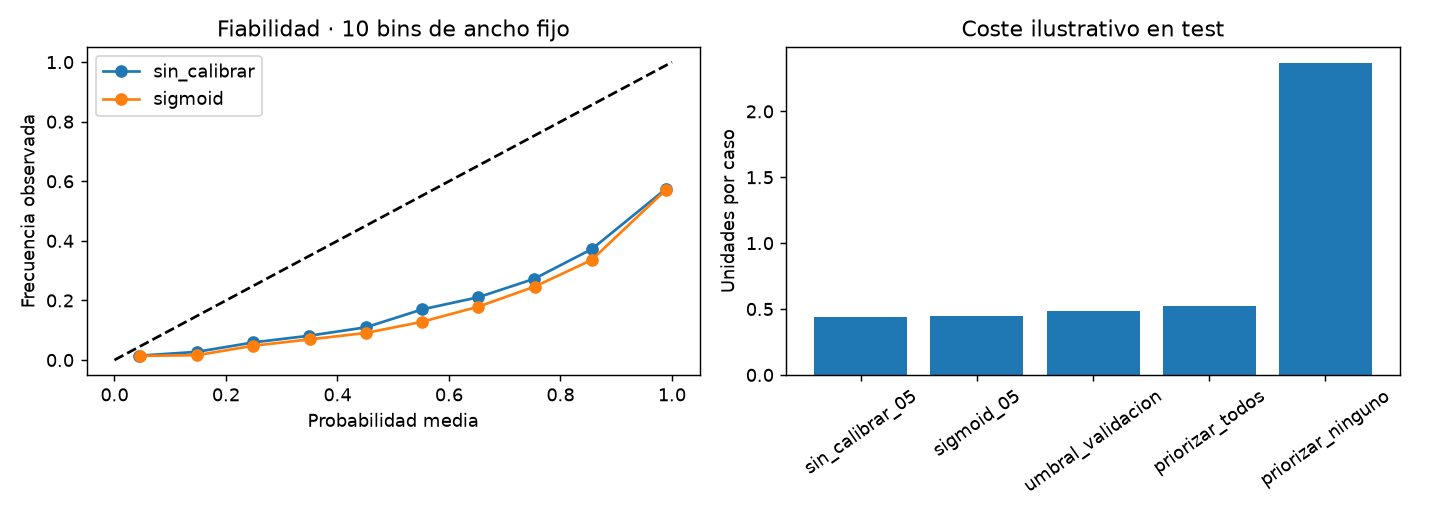

In [2]:
from subscription_churn.flujo import evaluar
display(Markdown(evaluar(PROJECT_ROOT)))

from IPython.display import Image
import pandas as pd
display(pd.read_csv(PROJECT_ROOT/"reports/evaluacion/calibracion_test.csv"))
display(pd.read_csv(PROJECT_ROOT/"reports/evaluacion/politicas_test.csv"))
display(Image(filename=str(PROJECT_ROOT/"reports/evaluacion/decisiones.png")))

## Alertas de la ejecucion

Avisos agrupados con descripcion generica, acciones sugeridas y detalle original. Los errores de celda no se ocultan.

In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from subscription_churn.informe import generar_informe
generar_informe(PROJECT_ROOT)


WindowsPath('D:/portafolio/Analisis/churn/SubscriptionChurn/reports/informe_final/informe_final.md')